> **ANNEX.** Baselines for the **classifier** (untrained Qwen, Haiku, Sonnet). This is the first experiment we ran, before moving on to the pattern reviewer.
>
> Main reading: `01_FINAL_full_story` · engine: `02_deterministic_engine` · map: `00_INDEX`.

# 03 · Baselines: where do we stand before training?
Everything we have measured, in one place. Each cell reads the saved results (they can be re-run).

**Models:** Qwen3.5-4B and 9B (not fine-tuned, local on this machine) · Haiku and Sonnet (from the Claude session, blind, with the real v3 prompt).
**Two sets:** (A) *held-out* of 144 hand-written lines, with the answers of a single annotator; (B) *hard synthetic benchmark v1*: 122 receipts / 417 lines, labels by construction.
Decision log: `finetune/FINETUNE_LOG.md`.

In [1]:
import json, glob, collections
from pathlib import Path
import pandas as pd
ROOT = Path.home() / 'finetune_project'
RESTR = set(['alcohol', 'tobacco', 'personal_electronics', 'gift', 'gift_card', 'household_goods', 'personal_care', 'clothing', 'gambling', 'jewelry'])
def load_pred(path_or_glob):
    pred = {}
    for f in sorted(glob.glob(str(path_or_glob))):
        d = json.load(open(f))
        items = d if isinstance(d, list) else [dict(receipt_id=k, lines=v.get('lines')) for k, v in d.items()]
        for r in items:
            for l in (r.get('lines') or []):
                if isinstance(l, dict) and 'line_id' in l: pred[l['line_id']] = l
    return pred
def wilson(k, n, z=1.96):
    if n == 0: return (0, 0)
    p = k/n; d = 1+z*z/n; c = p+z*z/(2*n); m = z*((p*(1-p)/n+z*z/(4*n*n))**.5)
    return round((c-m)/d*100, 1), round((c+m)/d*100, 1)
def score(pred, X, excl=()):
    ids = [i for i in X if i not in excl]; got = [i for i in ids if i in pred]
    ex = [i for i in got if pred[i].get('category') == X[i]['category']]
    al = [i for i in got if pred[i].get('category') == X[i]['category'] or pred[i].get('category') in X[i].get('acceptable_alternatives', [])]
    err = [i for i in got if i not in ex]
    lowe = [i for i in err if pred[i].get('confidence') == 'low']
    lowo = [i for i in ex if pred[i].get('confidence') == 'low']
    return dict(lines=len(ids), answered=len(got), exact=len(ex), exact_pct=round(100*len(ex)/max(1,len(got)),1),
                CI95=wilson(len(ex), len(got)), with_alternatives=len(al), errors=len(err), errors_with_low=len(lowe),
                false_alarms_low=len(lowo))
print('ready')

ready


## A · Held-out (144 lines, a single annotator)
Untrained Qwen, with the real v3 prompt. Haiku does not appear here because its run uses the project cache (**137 to 139 out of 144**, a range depending on the prompt version).

In [2]:
X = {}
for l in open(ROOT/'validator/data_heldout/expected.jsonl'):
    d = json.loads(l); X[d['line_id']] = d
rows = []
for tag, name in [('qwen4b','Qwen3.5-4B bf16'), ('qwen9b4','Qwen3.5-9B 4-bit')]:
    f = ROOT/f'results/{tag}_heldout.json'
    if f.exists():
        s = score(load_pred(f), X); s['model'] = name; rows.append(s)
    else:
        rows.append(dict(model=name, note='still running'))
pd.DataFrame(rows).set_index('model')

,lines,answered,exact,exact_pct,CI95,with_alternatives,errors,errors_with_low,false_alarms_low
model,,,,,,,,,
Qwen3.5-4B bf16,144,144,120,83.3,"(76.4, 88.5)",131,24,0,4
Qwen3.5-9B 4-bit,144,144,117,81.2,"(74.1, 86.8)",129,27,0,4


## B · Hard synthetic benchmark v1 (417 scored lines)
3 lines that already existed in the real data are excluded (decontamination). **Warning:** the lines were written by Sonnet and then classified by Sonnet, so the benchmark is probably easier for it than an independent one would be.

In [3]:
XB = {}
for l in open(ROOT/'data_synth/hardv1_expected.jsonl'):
    d = json.loads(l); XB[d['line_id']] = d
excl = {f['line_id'] for f in json.load(open(ROOT/'data_synth/hardv1_flagged_decontam.json'))}
src = {'Haiku (session)': ROOT/'data_synth/audit_out/haiku_in*.json', 'Sonnet (session)': ROOT/'data_synth/audit_out/sonnet_in*.json',
       'Qwen3.5-4B bf16': ROOT/'results/qwen4b_hardv1.json', 'Qwen3.5-9B 4-bit': ROOT/'results/qwen9b4_hardv1.json', 'Gemma3-12B 4-bit (other family)': ROOT/'results/gemma12_hardv1.json'}
rows, preds = [], {}
for name, p in src.items():
    pr = load_pred(p)
    if pr:
        preds[name] = pr; s = score(pr, XB, excl); s['model'] = name; rows.append(s)
    else:
        rows.append(dict(model=name, note='still running'))
TB = pd.DataFrame(rows).set_index('model'); TB

,lines,answered,exact,exact_pct,CI95,with_alternatives,errors,errors_with_low,false_alarms_low,note
model,,,,,,,,,,
Haiku (session),417.0,417.0,410.0,98.3,"(96.6, 99.2)",415.0,7.0,2.0,1.0,NaN
Sonnet (session),417.0,417.0,412.0,98.8,"(97.2, 99.5)",416.0,5.0,0.0,5.0,NaN
Qwen3.5-4B bf16,417.0,417.0,367.0,88.0,"(84.5, 90.8)",394.0,50.0,2.0,0.0,NaN
Qwen3.5-9B 4-bit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,still running
Gemma3-12B 4-bit (other family),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,still running


### Reading
- **exact / exact_pct**: the category matches the constructed label.
- **errors_with_low**: of the errors, how many the model flagged with `low` confidence (which would trigger EXC-03 and send the receipt to review). Higher is better.
- **false_alarms_low**: correct lines flagged `low` (unnecessary human review). Lower is better.


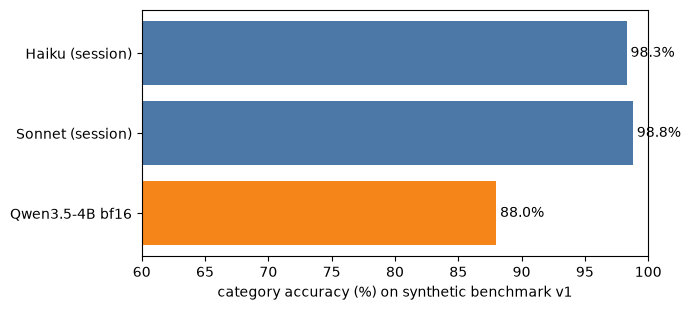

In [4]:
import matplotlib.pyplot as plt
d = TB.dropna(subset=['exact_pct'])
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(d.index, d['exact_pct'], color=['#4c78a8' if 'Qwen' not in n else '#f58518' for n in d.index])
ax.set_xlim(60, 100); ax.set_xlabel('category accuracy (%) on synthetic benchmark v1'); ax.invert_yaxis()
for i, v in enumerate(d['exact_pct']): ax.text(v + .3, i, f'{v}%', va='center')
plt.tight_layout(); plt.show()

### By trap type (slice)

In [5]:
def by(col):
    out = {}
    for name, pr in preds.items():
        c = collections.defaultdict(lambda: [0, 0])
        for i, x in XB.items():
            if i in excl or i not in pr: continue
            c[x[col]][1] += 1; c[x[col]][0] += pr[i].get('category') == x['category']
        out[name] = {k: f'{v[0]}/{v[1]}' for k, v in sorted(c.items())}
    return pd.DataFrame(out)
by('slice')

,Haiku (session),Sonnet (session),Qwen3.5-4B bf16
brand_no_hint,40/40,40/40,37/40
dirty_text,52/53,53/53,49/53
extension_items,34/34,34/34,28/34
gift_vs_goods,35/35,34/35,31/35
injection,18/18,18/18,16/18
plain,43/43,43/43,41/43
recipient_in_text,43/43,43/43,41/43
restricted_boundary,36/38,37/38,37/38
service_vs_tip,37/37,37/37,37/37
trap_names_lie,72/76,73/76,50/76


### By language

In [6]:
by('language')

,Haiku (session),Sonnet (session),Qwen3.5-4B bf16
de,72/72,72/72,63/72
en,99/102,101/102,85/102
es,63/64,63/64,59/64
fr,53/53,53/53,47/53
ja,80/83,81/83,76/83
pt,43/43,42/43,37/43


### Qwen errors that frontier models get right (what would need to be learned)

In [7]:
if 'Qwen3.5-4B bf16' in preds and 'Haiku (session)' in preds:
    q, h = preds['Qwen3.5-4B bf16'], preds['Haiku (session)']
    desc = {}
    for l in open(ROOT/'data_synth/hardv1_receipts.jsonl'):
        r = json.loads(l)
        for li in r['line_items']: desc[li['line_id']] = li['description_raw']
    rows = [dict(line=desc[i], correct=XB[i]['category'], qwen4b=q[i].get('category'), qwen_conf=q[i].get('confidence'), haiku=h.get('category') if False else h[i].get('category'))
            for i in XB if i not in excl and i in q and i in h and q[i].get('category') != XB[i]['category'] and h[i].get('category') == XB[i]['category']]
    print(len(rows), 'lines where Qwen 4B fails and Haiku succeeds'); display(pd.DataFrame(rows).head(25))
else:
    print('no Qwen results on the benchmark yet')

44 lines where Qwen 4B fails and Haiku succeeds


,line,correct,qwen4b,qwen_conf,haiku
0,Kaffee mit Schuss Amaretto,alcohol,food_beverage,high,alcohol
1,"Heisse Zitrone mit Rum 0,3l",alcohol,food_beverage,high,alcohol
2,Logitech MX Master 3S,computer_accessory,personal_electronics,high,computer_accessory
3,GESCH.KORB WEIN-OPT. LEER,gift,household_goods,high,gift
4,"Obst-Box für Büro, 5 kg, saisonal",food_beverage,gift,high,food_beverage
5,Schokoladen-Adventskalender Zartbitter 24 Türchen,food_beverage,gift,high,food_beverage
6,Schokoladen-Gesichtsmaske Kakao & Honig,personal_care,household_goods,high,personal_care
7,KOKOS-DUSCHGEL 250ML,personal_care,household_goods,high,personal_care
8,Bleistift-Lippenkonturenstift Rosé,personal_care,office_supplies,high,personal_care
9,JD&Coke dbl,alcohol,food_beverage,high,alcohol


## Next steps
1. Decide with these numbers whether to train: the real gap is between untrained Qwen and the frontier models.
2. Synthetic training data (a batch separate from the benchmark).
3. LoRA training with a verifiable reward, and re-measure here with the same sets.